In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, confusion_matrix, precision_recall_curve, auc

# Asegurar que la raíz del proyecto esté en el path
root_path = Path("..").resolve() if Path("../src").exists() else Path(".").resolve()
if str(root_path) not in sys.path:
    sys.path.append(str(root_path))

import json
import joblib
from tensorflow import keras
from src.modelo import entrenar_modelo_trivial
from src.evaluacion import calcular_metricas, elegir_umbral, COSTO_FN, COSTO_FP

# Cargar las particiones (sin escalar) desde data/
X_train = pd.read_csv(root_path / "data" / "X_train.csv")
X_val   = pd.read_csv(root_path / "data" / "X_val.csv")
X_test  = pd.read_csv(root_path / "data" / "X_test.csv")
y_train = pd.read_csv(root_path / "data" / "y_train.csv").values.ravel()
y_val   = pd.read_csv(root_path / "data" / "y_val.csv").values.ravel()
y_test  = pd.read_csv(root_path / "data" / "y_test.csv").values.ravel()

# Mismo preprocesador que se ajustó con entrenamiento en entrenar.py
preprocesador = joblib.load(root_path / "modelos" / "preprocesador.pkl")
Xp_train = preprocesador.transform(X_train)
Xp_val = preprocesador.transform(X_val)

print(f"Dimensiones de entrenamiento - X: {X_train.shape}, y: {y_train.shape}")
print(f"Dimensiones de validación   - X: {X_val.shape}, y: {y_val.shape}")

Dimensiones de entrenamiento - X: (31638, 15), y: (31638,)
Dimensiones de validación   - X: (6777, 15), y: (6777,)


In [2]:
# 1. Línea Base Trivial (no se guarda: siempre predice "no suscribe")
modelo_trivial = entrenar_modelo_trivial(Xp_train, y_train)
y_pred_trivial = modelo_trivial.predict(Xp_val)

# 2. Línea Base Simple (Regresión Logística), versión guardada por entrenar.py
modelo_simple = joblib.load(root_path / "modelos" / "modelo_simple_logreg.pkl")
y_prob_simple = modelo_simple.predict_proba(Xp_val)[:, 1]

print("¡Modelos de línea base listos!")

¡Modelos de línea base listos!


In [3]:
# Redes neuronales guardadas por entrenar.py (no se vuelven a entrenar aquí)
mlp_v1 = keras.models.load_model(root_path / "modelos" / "mlp_v1.keras")
mlp_v2 = keras.models.load_model(root_path / "modelos" / "mlp_v2.keras")

y_prob_v1 = mlp_v1.predict(Xp_val, verbose=0).ravel()
y_prob_v2 = mlp_v2.predict(Xp_val, verbose=0).ravel()

# Umbral de cada modelo elegido en VALIDACIÓN según el costo de los errores (FN = 5, FP = 1)
umbral_simple = elegir_umbral(y_val, y_prob_simple)
umbral_v1 = elegir_umbral(y_val, y_prob_v1)
umbral_v2 = elegir_umbral(y_val, y_prob_v2)
y_pred_simple = (y_prob_simple >= umbral_simple).astype(int)
y_pred_v1 = (y_prob_v1 >= umbral_v1).astype(int)
y_pred_v2 = (y_prob_v2 >= umbral_v2).astype(int)

print(f"Umbrales elegidos -> LogReg: {umbral_simple}, MLP V1: {umbral_v1}, MLP V2: {umbral_v2}")

Umbrales elegidos -> LogReg: 0.57, MLP V1: 0.62, MLP V2: 0.58


In [4]:
modelos_eval = {
    "1. Trivial (Dummy)": (y_pred_trivial, None),
    "2. Lineal Simple (LogReg)": (y_pred_simple, y_prob_simple),
    "3. Red Neuronal V1 (MLP)": (y_pred_v1, y_prob_v1),
    "4. Red Neuronal V2 (MLP+Dropout)": (y_pred_v2, y_prob_v2)
}

resultados = []

for nombre, (y_p, y_prob) in modelos_eval.items():
    acc = np.mean(y_p == y_val)
    prec = precision_score(y_val, y_p, zero_division=0)
    rec = recall_score(y_val, y_p, zero_division=0)
    f1 = f1_score(y_val, y_p, zero_division=0)
    
    # Calcular PR-AUC si hay probabilidades
    if y_prob is not None:
        precision_c, recall_c, _ = precision_recall_curve(y_val, y_prob)
        pr_auc = auc(recall_c, precision_c)
    else:
        pr_auc = np.mean(y_val)  # un modelo sin puntajes tiene PR-AUC igual a la proporción de positivos

    resultados.append({
        "Modelo": nombre,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "PR-AUC": round(pr_auc, 4),
        "Costo/cliente": calcular_metricas(y_val, y_p, y_prob)["costo_por_cliente"]
    }
)

df_comparativa = pd.DataFrame(resultados)
display(df_comparativa)

,Modelo,Accuracy,Precision,Recall,F1-Score,PR-AUC,Costo/cliente
0,1. Trivial (Dummy),0.8830,0.0000,0.0000,0.0000,0.1170,0.5851
1,2. Lineal Simple (LogReg),0.8524,0.3962,0.4981,0.4413,0.4090,0.3825
2,3. Red Neuronal V1 (MLP),0.8579,0.4138,0.5145,0.4587,0.4098,0.3693
3,4. Red Neuronal V2 (MLP+Dropout),0.8541,0.4047,0.5246,0.4569,0.4111,0.3685


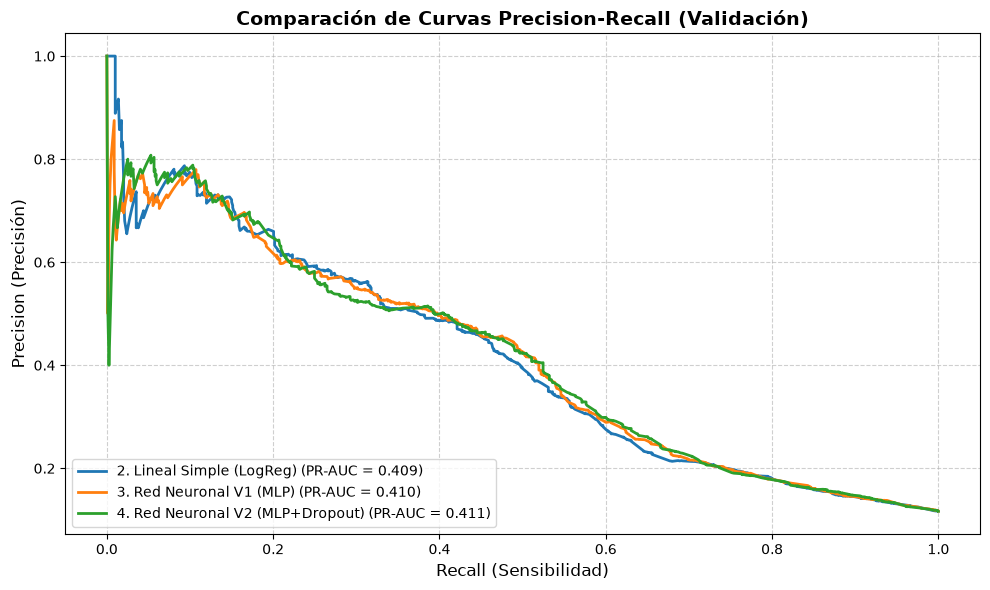

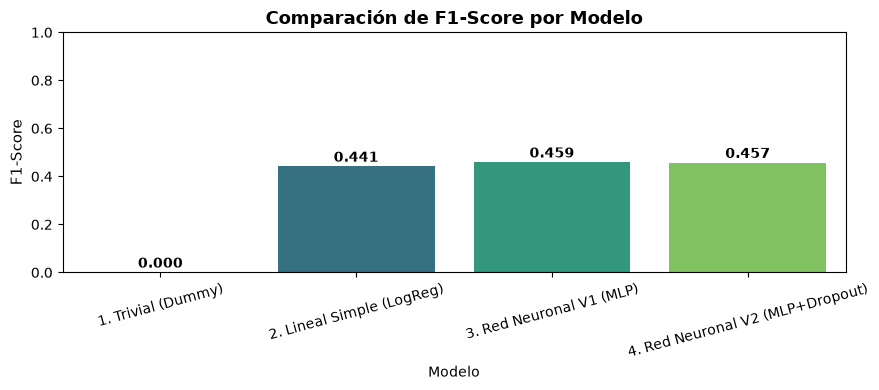

In [5]:
plt.figure(figsize=(10, 6))

# Graficar curva Precision-Recall para los modelos que tienen probabilidad
for nombre, (_, y_prob) in modelos_eval.items():
    if y_prob is not None:
        precision_c, recall_c, _ = precision_recall_curve(y_val, y_prob)
        pr_auc = auc(recall_c, precision_c)
        plt.plot(recall_c, precision_c, label=f"{nombre} (PR-AUC = {pr_auc:.3f})", linewidth=2)

plt.xlabel("Recall (Sensibilidad)", fontsize=12)
plt.ylabel("Precision (Precisión)", fontsize=12)
plt.title("Comparación de Curvas Precision-Recall (Validación)", fontsize=14, fontweight='bold')
plt.legend(loc="lower left", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Gráfico de barras comparativo de F1-Score
plt.figure(figsize=(9, 4))
sns.barplot(data=df_comparativa, x="Modelo", y="F1-Score", hue="Modelo", palette="viridis", legend=False)
plt.title("Comparación de F1-Score por Modelo", fontsize=13, fontweight='bold')
plt.ylim(0, 1.0)
plt.xticks(rotation=15)
plt.ylabel("F1-Score", fontsize=11)
for index, row in df_comparativa.iterrows():
    plt.text(index, row["F1-Score"] + 0.02, f"{row['F1-Score']:.3f}", color='black', ha="center", fontweight='bold')
plt.tight_layout()
plt.show()

### Elección del Umbral según el Costo de los Errores

Un falso negativo (no llamar a un cliente que sí habría suscrito) cuesta 5 y un falso positivo (una llamada de más) cuesta 1. Para cada umbral entre 0.01 y 0.99 se calcula el costo total en validación y se elige el menor, en lugar de usar 0.5 por defecto.

Versión promovida: MLP_Version_2 | umbral: 0.58
Motivo: Menor costo por cliente en validación (0.3685).


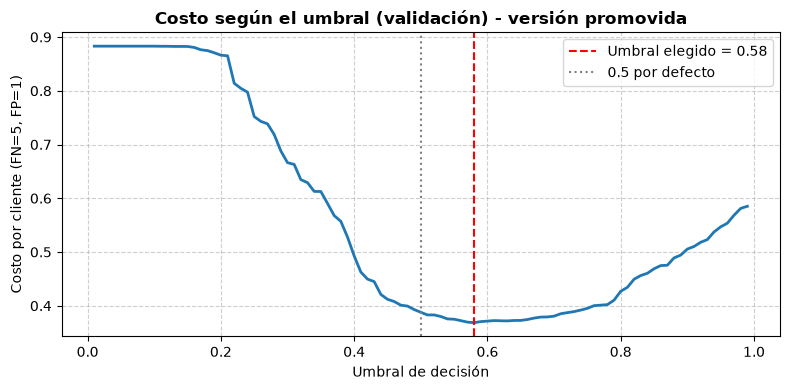

In [6]:
promovido = json.load(open(root_path / "modelos" / "modelo_promovido.json", encoding="utf-8"))
print("Versión promovida:", promovido["modelo"], "| umbral:", promovido["umbral"])
print("Motivo:", promovido["motivo"])

y_prob_promovido = {"MLP_Version_1": y_prob_v1, "MLP_Version_2": y_prob_v2,
                    "Modelo_Simple_RegrLog": y_prob_simple}[promovido["modelo"]]
umbrales = np.round(np.arange(0.01, 1.0, 0.01), 2)
costos = [calcular_metricas(y_val, (y_prob_promovido >= u).astype(int), y_prob_promovido)["costo_por_cliente"] for u in umbrales]

plt.figure(figsize=(8, 4))
plt.plot(umbrales, costos, linewidth=2)
plt.axvline(promovido["umbral"], color="red", linestyle="--", label=f"Umbral elegido = {promovido['umbral']}")
plt.axvline(0.5, color="gray", linestyle=":", label="0.5 por defecto")
plt.xlabel("Umbral de decisión")
plt.ylabel(f"Costo por cliente (FN={COSTO_FN}, FP={COSTO_FP})")
plt.title("Costo según el umbral (validación) - versión promovida", fontweight="bold")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Evaluación Final en Prueba (una sola vez)

La versión ganadora se eligió **solo con validación**. El conjunto de prueba se usa una única vez, con la versión promovida y su umbral.

              precision    recall  f1-score   support

 No suscribe      0.933     0.895     0.913      5987
    Suscribe      0.393     0.512     0.444       793

    accuracy                          0.850      6780
   macro avg      0.663     0.704     0.679      6780
weighted avg      0.869     0.850     0.859      6780



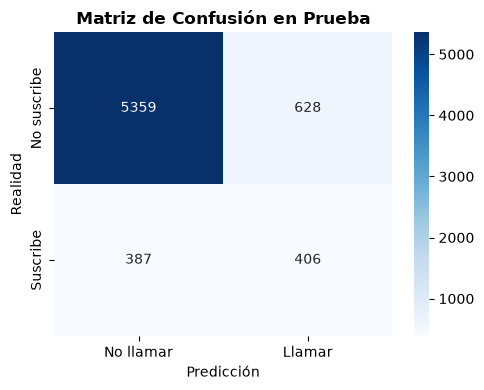

In [7]:
modelo_promovido = {"MLP_Version_1": mlp_v1, "MLP_Version_2": mlp_v2, "Modelo_Simple_RegrLog": modelo_simple}[promovido["modelo"]]
Xp_test = preprocesador.transform(X_test)
if "MLP" in promovido["modelo"]:
    y_prob_test = modelo_promovido.predict(Xp_test, verbose=0).ravel()
else:
    y_prob_test = modelo_promovido.predict_proba(Xp_test)[:, 1]
y_pred_test = (y_prob_test >= promovido["umbral"]).astype(int)

print(classification_report(y_test, y_pred_test, target_names=["No suscribe", "Suscribe"], digits=3))

cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No llamar", "Llamar"], yticklabels=["No suscribe", "Suscribe"])
plt.xlabel("Predicción")
plt.ylabel("Realidad")
plt.title("Matriz de Confusión en Prueba", fontweight="bold")
plt.tight_layout()
plt.show()

### Equidad: ¿el error cambia entre ocupaciones?

`job` es la única variable demográfica que usa el modelo, por lo que se revisa el recall y la precisión por ocupación en el conjunto de prueba.

In [8]:
ficha_ganadora = {"MLP_Version_1": "ficha_mlp_v1.json", "MLP_Version_2": "ficha_mlp_v2.json",
                  "Modelo_Simple_RegrLog": "ficha_logreg.json"}[promovido["modelo"]]
ficha = json.load(open(root_path / "modelos" / ficha_ganadora, encoding="utf-8"))
equidad = pd.DataFrame(ficha["equidad_prueba_por_ocupacion"]).T.sort_values("recall")
display(equidad)

,clientes,suscriben,recall,precision
blue-collar,1422.0,111.0,0.2793,0.5345
self-employed,244.0,30.0,0.3333,0.2703
entrepreneur,224.0,21.0,0.3810,0.5714
housemaid,158.0,20.0,0.4000,0.5333
services,632.0,47.0,0.4043,0.4750
unemployed,174.0,33.0,0.4545,0.3125
management,1435.0,193.0,0.4870,0.3456
unknown,34.0,2.0,0.5000,0.3333
admin.,788.0,91.0,0.5495,0.3571
technician,1173.0,131.0,0.5954,0.4968


### Versionado: una Ficha Técnica por Versión

In [9]:
filas = []
for archivo in ["ficha_trivial.json", "ficha_logreg.json", "ficha_mlp_v1.json", "ficha_mlp_v2.json"]:
    f = json.load(open(root_path / "modelos" / archivo, encoding="utf-8"))
    filas.append({
        "Ficha": archivo,
        "Modelo": f["modelo"],
        "Fecha": f["timestamp"][:19],
        "Umbral": f["umbral"]["valor"],
        "Costo/cliente (val)": f["metricas_validacion"]["costo_por_cliente"],
        "Promovido": f["promovido"],
        "Evaluado en prueba": f["metricas_prueba_final"] != "No evaluado en prueba",
    })
display(pd.DataFrame(filas))

,Ficha,Modelo,Fecha,Umbral,Costo/cliente (val),Promovido,Evaluado en prueba
0,ficha_trivial.json,Modelo_Trivial,2026-10-22T19:13:50,NaN,0.5851,False,False
1,ficha_logreg.json,Modelo_Simple_RegrLog,2026-10-22T19:13:50,0.57,0.3825,False,False
2,ficha_mlp_v1.json,MLP_Version_1,2026-10-22T19:13:50,0.62,0.3693,False,False
3,ficha_mlp_v2.json,MLP_Version_2,2026-10-22T19:13:50,0.58,0.3685,True,True


### Conclusiones de la Etapa 4 (Evaluación y Versionado)

1. **Evidencia frente al Desbalance**:
   - La línea base trivial obtiene un Accuracy alto pero un F1-Score y Recall nulos, evidenciando que el accuracy no es una métrica válida en este dataset desbalanceado.
2. **Umbral según el costo**:
   - El umbral de cada modelo se eligió en validación minimizando el costo de los errores (FN = 5, FP = 1), en lugar de usar 0.5.
3. **Selección del Modelo Ganador**:
   - Se promovió la versión con menor costo por cliente en validación (`modelos/modelo_promovido.json`). Las diferencias entre las dos redes son muy pequeñas.
4. **Prueba y versionado**:
   - El conjunto de prueba se usó una sola vez, con la versión promovida. Cada versión tiene su propia ficha técnica JSON con fecha, datos, variables, hiperparámetros, umbral y métricas; solo la promovida tiene métricas de prueba.
5. **Equidad**:
   - El recall cambia entre ocupaciones (es mayor en estudiantes y jubilados y menor en obreros). El sistema solo prioriza llamadas y siempre permite derivar a un asesor humano, pero estas métricas deben revisarse en cada nueva versión.